BÀI 2: MNIST

Cell 0: Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

Câu a) Đọc bộ dữ liệu train, test của MNIST từ Keras

In [2]:
print("Lê Anh Pha - 6451071056")

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Đã đọc xong bộ dữ liệu MNIST")

Lê Anh Pha - 6451071056
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Đã đọc xong bộ dữ liệu MNIST


Câu b) In ra kích thước của tập train, test

In [3]:
print("Lê Anh Pha - 6451071056")

print("train_images:", train_images.shape)
print("train_labels:", train_labels.shape)
print("test_images :", test_images.shape)
print("test_labels :", test_labels.shape)

Lê Anh Pha - 6451071056
train_images: (60000, 28, 28)
train_labels: (60000,)
test_images : (10000, 28, 28)
test_labels : (10000,)


Câu c) Chuẩn hóa các giá trị pixel về đoạn [0,1]

In [4]:
print("Lê Anh Pha - 6451071056")

print("Trước chuẩn hóa: min =", train_images.min(), "| max =", train_images.max())

train_images = train_images / 255.0
test_images = test_images / 255.0

print("Sau chuẩn hóa : min =", train_images.min(), "| max =", train_images.max())

Lê Anh Pha - 6451071056
Trước chuẩn hóa: min = 0 | max = 255
Sau chuẩn hóa : min = 0.0 | max = 1.0


Câu d) Chia tập train thành train và validation theo tỷ lệ 8:2

In [5]:
print("Lê Anh Pha - 6451071056")

train_images, validation_images, train_labels, validation_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42)

print("train_images     :", train_images.shape)
print("train_labels     :", train_labels.shape)
print("validation_images:", validation_images.shape)
print("validation_labels:", validation_labels.shape)

Lê Anh Pha - 6451071056
train_images     : (48000, 28, 28)
train_labels     : (48000,)
validation_images: (12000, 28, 28)
validation_labels: (12000,)


Câu e) Xây dựng Neural Network

In [6]:
print("Lê Anh Pha - 6451071056")

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                        # 28x28 -> vector 784 chiều
    Dense(128, activation='relu'),    # fully connected, 128 neuron
    Dropout(0.2),                     # tắt ngẫu nhiên 20% neuron khi huấn luyện
    Dense(10, activation='softmax')   # 10 lớp (chữ số 0-9)
])

model.summary()

Lê Anh Pha - 6451071056


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Câu f) Biên dịch mô hình

In [7]:
print("Lê Anh Pha - 6451071056")

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("Đã biên dịch mô hình: optimizer = adam, loss = sparse_categorical_crossentropy, metric = accuracy")

Lê Anh Pha - 6451071056
Đã biên dịch mô hình: optimizer = adam, loss = sparse_categorical_crossentropy, metric = accuracy


Câu g) Huấn luyện mô hình (epoch = 5, batch_size = 32)

In [8]:
print("Lê Anh Pha - 6451071056")

history = model.fit(train_images, train_labels,
                    validation_data=(validation_images, validation_labels),
                    epochs=5,
                    batch_size=32)

Lê Anh Pha - 6451071056
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9079 - loss: 0.3194 - val_accuracy: 0.9545 - val_loss: 0.1630
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9548 - loss: 0.1556 - val_accuracy: 0.9659 - val_loss: 0.1168
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9653 - loss: 0.1154 - val_accuracy: 0.9688 - val_loss: 0.0988
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9713 - loss: 0.0951 - val_accuracy: 0.9745 - val_loss: 0.0860
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9752 - loss: 0.0806 - val_accuracy: 0.9739 - val_loss: 0.0844


Câu h) Vẽ biểu đồ accuracy, loss sau mỗi epoch

Lê Anh Pha - 6451071056


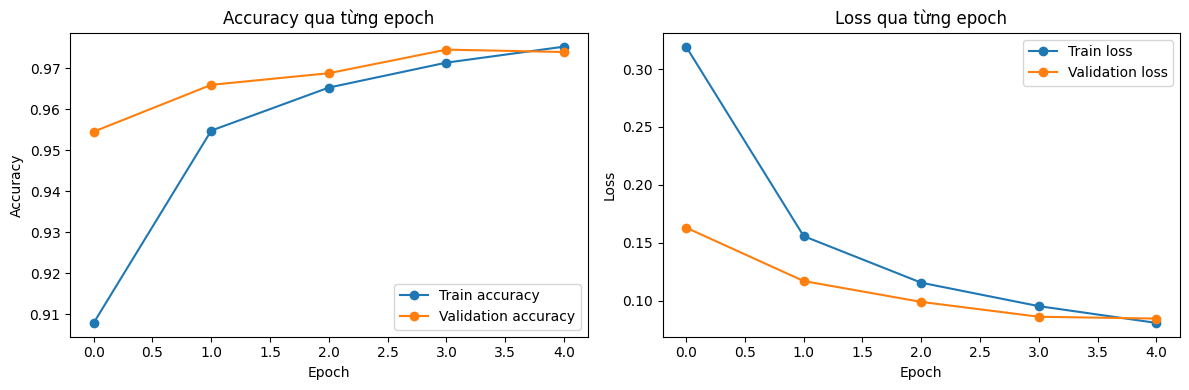

In [9]:
print("Lê Anh Pha - 6451071056")

plt.figure(figsize=(12, 4))

# Biểu đồ accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], marker='o', label='Train accuracy')
plt.plot(history.history['val_accuracy'], marker='o', label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy qua từng epoch')
plt.legend()

# Biểu đồ loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], marker='o', label='Train loss')
plt.plot(history.history['val_loss'], marker='o', label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss qua từng epoch')
plt.legend()

plt.tight_layout()
plt.show()

Câu i) Dự đoán phân lớp cho tập test

In [10]:
print("Lê Anh Pha - 6451071056")

y_prob = model.predict(test_images)        # xác suất của từng lớp cho mỗi ảnh
y_pred = np.argmax(y_prob, axis=1)         # chọn lớp có xác suất lớn nhất

print("Kích thước ma trận xác suất:", y_prob.shape)
print("10 nhãn dự đoán đầu tiên:", y_pred[:10])
print("10 nhãn thực tế đầu tiên:", test_labels[:10])

Lê Anh Pha - 6451071056
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Kích thước ma trận xác suất: (10000, 10)
10 nhãn dự đoán đầu tiên: [7 2 1 0 4 1 4 9 5 9]
10 nhãn thực tế đầu tiên: [7 2 1 0 4 1 4 9 5 9]


Câu j) Accuracy trên tập test

In [11]:
print("Lê Anh Pha - 6451071056")

acc = accuracy_score(test_labels, y_pred)
print("Accuracy trên tập test:", acc)
print(f"Accuracy trên tập test: {acc*100:.2f}%")

Lê Anh Pha - 6451071056
Accuracy trên tập test: 0.9766
Accuracy trên tập test: 97.66%


Câu k) Precision, Recall, F1-score từng lớp và trung bình

In [12]:
print("Lê Anh Pha - 6451071056")

print(classification_report(test_labels, y_pred, digits=4))

Lê Anh Pha - 6451071056
              precision    recall  f1-score   support

           0     0.9643    0.9918    0.9779       980
           1     0.9894    0.9850    0.9872      1135
           2     0.9694    0.9835    0.9764      1032
           3     0.9703    0.9713    0.9708      1010
           4     0.9837    0.9807    0.9822       982
           5     0.9807    0.9675    0.9740       892
           6     0.9801    0.9770    0.9786       958
           7     0.9701    0.9786    0.9743      1028
           8     0.9739    0.9589    0.9664       974
           9     0.9839    0.9693    0.9765      1009

    accuracy                         0.9766     10000
   macro avg     0.9766    0.9764    0.9764     10000
weighted avg     0.9767    0.9766    0.9766     10000



Câu l) Confusion matrix bằng heatmap

Lê Anh Pha - 6451071056


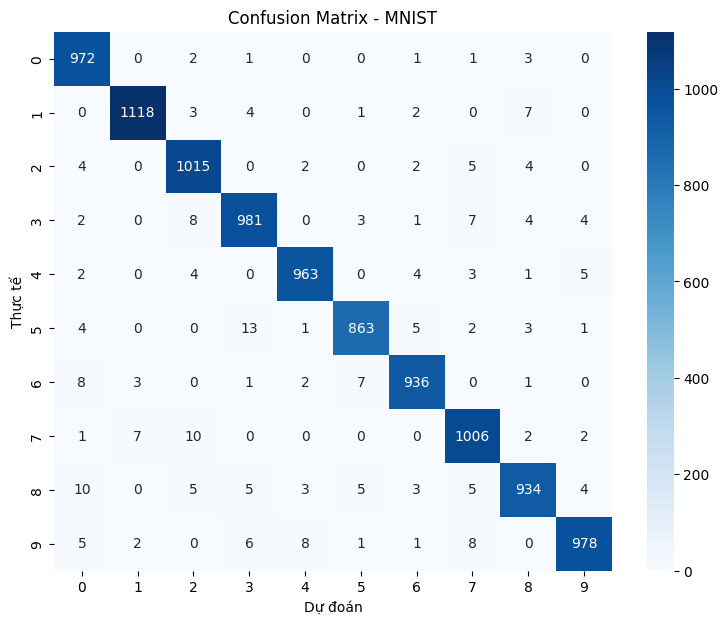

In [13]:
print("Lê Anh Pha - 6451071056")

cm = confusion_matrix(test_labels, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title('Confusion Matrix - MNIST')
plt.show()

Câu m) Kết quả phân lớp của 05 ảnh đầu tiên trong tập test

Lê Anh Pha - 6451071056


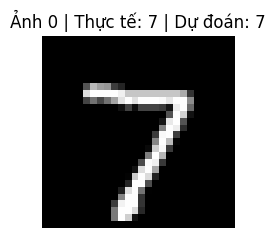

Ảnh 0: nhãn thực tế = 7, nhãn dự đoán = 7


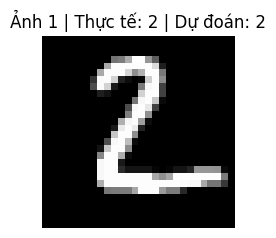

Ảnh 1: nhãn thực tế = 2, nhãn dự đoán = 2


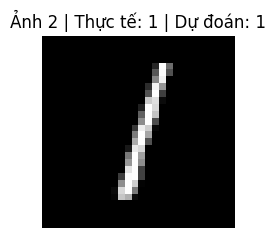

Ảnh 2: nhãn thực tế = 1, nhãn dự đoán = 1


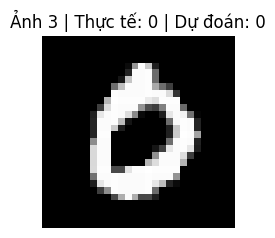

Ảnh 3: nhãn thực tế = 0, nhãn dự đoán = 0


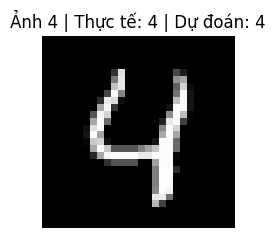

Ảnh 4: nhãn thực tế = 4, nhãn dự đoán = 4


In [14]:
print("Lê Anh Pha - 6451071056")

for image_index in range(5):
    # expand_dims: thêm chiều batch (28,28) -> (1,28,28) để đưa vào mô hình
    image = np.expand_dims(test_images[image_index], axis=0)
    prediction = model.predict(image, verbose=0)
    predicted_label = np.argmax(prediction)

    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(test_images[image_index], cmap='gray')
    plt.title(f"Ảnh {image_index} | Thực tế: {test_labels[image_index]} | Dự đoán: {predicted_label}")
    plt.axis('off')
    plt.show()

    print(f"Ảnh {image_index}: nhãn thực tế = {test_labels[image_index]}, nhãn dự đoán = {predicted_label}")

Câu n) 05 kết quả đầu tiên phân lớp sai

Lê Anh Pha - 6451071056
Tổng số ảnh dự đoán sai: 234


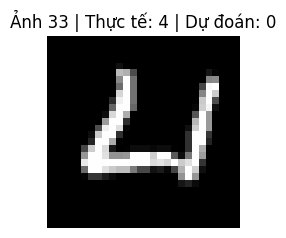

Ảnh 33: nhãn thực tế = 4, nhãn dự đoán sai = 0


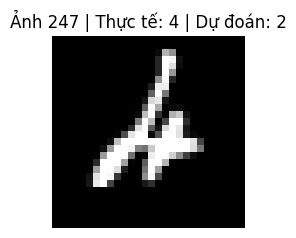

Ảnh 247: nhãn thực tế = 4, nhãn dự đoán sai = 2


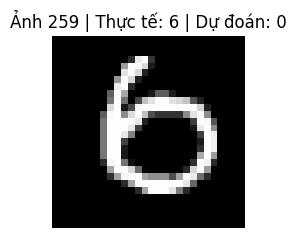

Ảnh 259: nhãn thực tế = 6, nhãn dự đoán sai = 0


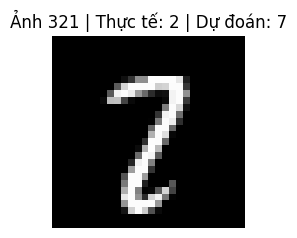

Ảnh 321: nhãn thực tế = 2, nhãn dự đoán sai = 7


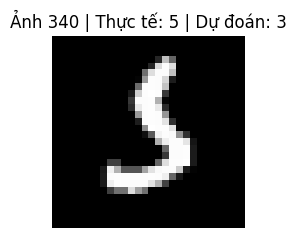

Ảnh 340: nhãn thực tế = 5, nhãn dự đoán sai = 3


In [15]:
print("Lê Anh Pha - 6451071056")

# Tìm vị trí các ảnh bị dự đoán sai, lấy 5 ảnh đầu tiên
wrong_idx = np.where(y_pred != test_labels)[0]
print("Tổng số ảnh dự đoán sai:", len(wrong_idx))

for i in wrong_idx[:5]:
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(test_images[i], cmap='gray')
    plt.title(f"Ảnh {i} | Thực tế: {test_labels[i]} | Dự đoán: {y_pred[i]}")
    plt.axis('off')
    plt.show()

    print(f"Ảnh {i}: nhãn thực tế = {test_labels[i]}, nhãn dự đoán sai = {y_pred[i]}")